In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Same gradients for both optimizers
gradients = [4, 2, 1, 3, 0.5, 2, 1, 0.2]

In [4]:
learning_rate = 0.1
epsilon = 1e-8

# Initial weights
weight_sgd = 10.0
weight_adagrad = 10.0

# AdaGrad's accumulated squared gradients
G = 0.0

In [5]:
sgd_weights = [weight_sgd]
adagrad_weights = [weight_adagrad]
effective_lrs = []

In [6]:
for gradient in gradients:

    # Ordinary SGD
    weight_sgd = weight_sgd - learning_rate * gradient
    sgd_weights.append(weight_sgd)

    # AdaGrad
    G += gradient ** 2

    effective_lr = learning_rate / (np.sqrt(G) + epsilon)
    effective_lrs.append(effective_lr)

    weight_adagrad = weight_adagrad - effective_lr * gradient
    adagrad_weights.append(weight_adagrad)

In [7]:
# Display results
print("Step | SGD Weight | AdaGrad Weight | AdaGrad Effective LR")
print("-" * 62)

for step in range(len(gradients) + 1):
    if step == 0:
        print(f"{step:4} | {sgd_weights[step]:10.5f} | "
              f"{adagrad_weights[step]:14.5f} | Initial LR: {learning_rate}")
    else:
        print(f"{step:4} | {sgd_weights[step]:10.5f} | "
              f"{adagrad_weights[step]:14.5f} | "
              f"{effective_lrs[step - 1]:.6f}")

Step | SGD Weight | AdaGrad Weight | AdaGrad Effective LR
--------------------------------------------------------------
   0 |   10.00000 |       10.00000 | Initial LR: 0.1
   1 |    9.60000 |        9.90000 | 0.025000
   2 |    9.40000 |        9.85528 | 0.022361
   3 |    9.30000 |        9.83346 | 0.021822
   4 |    9.00000 |        9.77868 | 0.018257
   5 |    8.95000 |        9.76959 | 0.018182
   6 |    8.75000 |        9.73542 | 0.017087
   7 |    8.65000 |        9.71858 | 0.016843
   8 |    8.63000 |        9.71521 | 0.016833


## Compare the weights

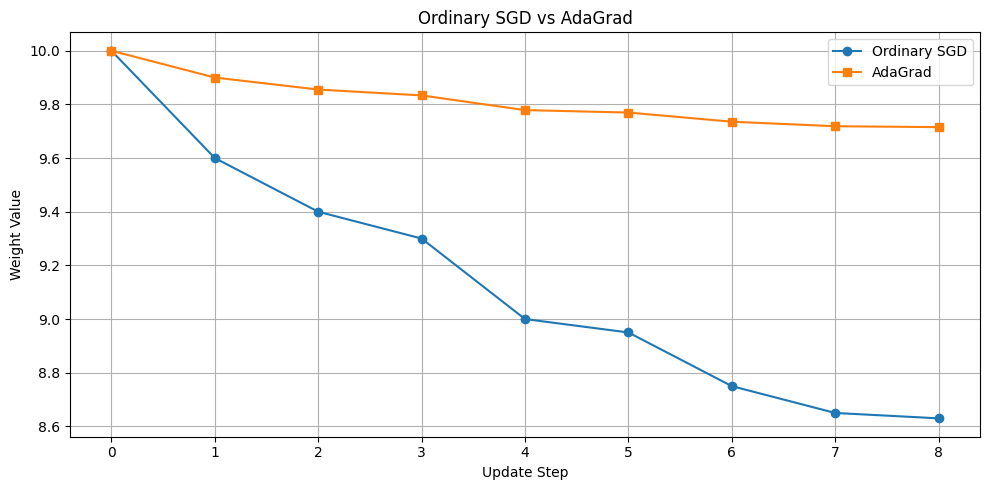

In [8]:
steps = range(len(gradients) + 1)

plt.figure(figsize=(10, 5))
plt.plot(steps, sgd_weights, marker="o", label="Ordinary SGD")
plt.plot(steps, adagrad_weights, marker="s", label="AdaGrad")

plt.xlabel("Update Step")
plt.ylabel("Weight Value")
plt.title("Ordinary SGD vs AdaGrad")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

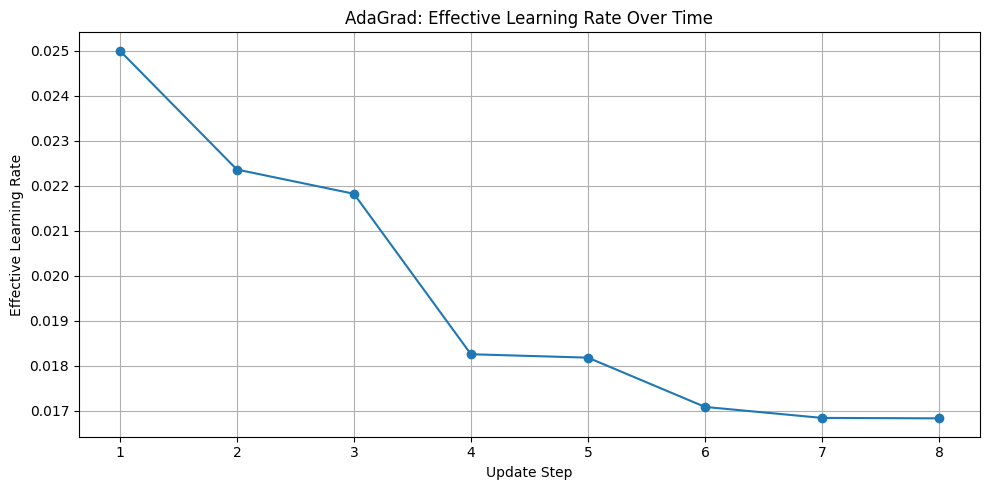

In [9]:
# Plot AdaGrad's changing learning rate
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(gradients) + 1),
         effective_lrs, marker="o")

plt.xlabel("Update Step")
plt.ylabel("Effective Learning Rate")
plt.title("AdaGrad: Effective Learning Rate Over Time")
plt.grid(True)
plt.tight_layout()
plt.show()
